# Moto Micro Tours — A Booking & Cost Sharing Service for Motorcycle Day Trips

# Description

**Service**
Riders (“**motards**”) create a **tour** and can edit(add, delete...) 1..n motards to the same tour (a “tour group”), other motards can request to join the tour as well. Each motard has their own seat capacity (e.g., 1 pillion, or convoy slots). A **participant** views the tour and then picks **one motard** to interact with **1-to-1**.

**Key rules you specified**

* Booking is **1-to-1**: a participant requests a seat **from one chosen motard** inside the tour.
* The participant can **chat first**, and can **review the motard’s profile, records, and comments** before sending the request.
* The booking request includes an **option to opt-in to cost-sharing** (fuel/tolls split) for later settlement; **but** the participant **must still pay the fixed seat price** to confirm.
* **Revenue split** on seat price: **50% platform / 50% motard** (system settles payouts).
* (Optional later) cost-sharing can be settled off-platform or via a later on-platform flow.

**MVP scope**

* Accounts, login; roles: **Motard** and **Participant** (a user can be both but acts per context).
* Tours (title, schedule, locations as plain text), **tour group**: attach motards with per-motard capacity & price/seat.
* Discovery/search by date/area/price.
* **Motard profile** with rating/reviews/history.
* **Pre-booking chat** (participant ↔ selected motard).
* **Request booking** (includes: accept safety rules, emergency contact, **cost-sharing opt-in** flag).
* **Approval** by the motard → **payment link** → **fixed seat price paid** → booking confirmed.
* Basic refunds/cancellations (mock).
* **Payout ledger** for the 50/50 split (mock settlement).

# Use Case Diagram

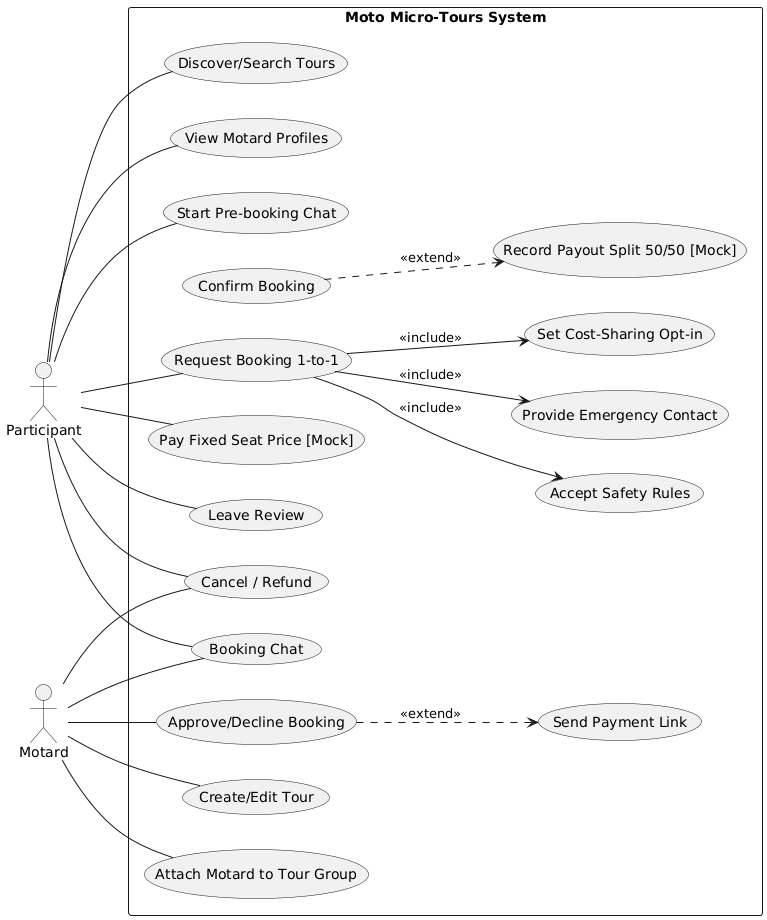

**Actors**

* **Participant**
* **Motard** (organizer-side actor attached to a tour group)
* *(Internal)* **Payout Service [mock]**

**Use cases**

* **UC1: Create/Edit Tour** *(Motard who initiates a tour)*
* **UC2: Attach Motard to Tour Group** *(add/remove motards; set capacity & price/seat per motard)*
* **UC3: Discover/Search Tours** *(Participant)*
* **UC3b: View Motard Profiles (in a tour)** *(ratings, history, comments)*
* **UC4: Start Pre-booking Chat** *(Participant ↔ chosen Motard, before requesting)*
* **UC5: Request Booking (1-to-1)** *(Participant → chosen Motard; includes safety rules, emergency contact, cost-sharing opt-in)*

  * *includes* **UC5a: Accept Safety Rules**
  * *includes* **UC5b: Provide Emergency Contact**
  * *includes* **UC5c: Set Cost-Sharing Opt-in Flag**
* **UC6: Approve/Decline Booking** *(Motard)*

  * *on approve → extends* **UC7: Send Payment Link**
* **UC8: Pay Fixed Seat Price (Mock)** *(Participant)*
* **UC9: Confirm Booking** *(System after successful payment)*

  * *extends* **UC10: Record Payout Split (50/50)** *(Payout Service mock)*
* **UC11: Cancel / Refund (rules)** *(Participant or Motard; system applies mock refund rules)*
* **UC12: Booking Chat** *(Participant ↔ Motard; after request; separate from pre-booking chat)*
* **UC13 (Optional later): Leave Review for Motard**

**PlantUML (Use Case)**

```plantuml
@startuml
left to right direction
actor Participant
actor Motard
rectangle "Moto Micro-Tours System" {
  (Create/Edit Tour) as UC1
  (Attach Motard to Tour Group) as UC2
  (Discover/Search Tours) as UC3
  (View Motard Profiles) as UC3b
  (Start Pre-booking Chat) as UC4
  (Request Booking 1-to-1) as UC5
  (Accept Safety Rules) as UC5a
  (Provide Emergency Contact) as UC5b
  (Set Cost-Sharing Opt-in) as UC5c
  (Approve/Decline Booking) as UC6
  (Send Payment Link) as UC7
  (Pay Fixed Seat Price [Mock]) as UC8
  (Confirm Booking) as UC9
  (Record Payout Split 50/50 [Mock]) as UC10
  (Cancel / Refund) as UC11
  (Booking Chat) as UC12
  (Leave Review) as UC13

  UC5 --> UC5a : <<include>>
  UC5 --> UC5b : <<include>>
  UC5 --> UC5c : <<include>>
  UC6 ..> UC7 : <<extend>>
  UC9 ..> UC10 : <<extend>>
}

Participant -- UC3
Participant -- UC3b
Participant -- UC4
Participant -- UC5
Participant -- UC8
Participant -- UC11
Participant -- UC12
Participant -- UC13

Motard -- UC1
Motard -- UC2
Motard -- UC6
Motard -- UC11
Motard -- UC12
@enduml
```

**Happy path**

1. Participant discovers a tour → views motard list for that tour → opens a motard profile → **starts pre-booking chat**.
2. Participant **requests booking (1-to-1)** from that motard, accepting safety rules, giving emergency contact, and optionally **opting into cost-sharing**.
3. Motard **approves** → system sends **payment link** → Participant **pays fixed seat price**.
4. System **confirms booking** and **records 50/50 payout** (mock).
5. They can continue chatting inside **booking chat**.



# Class Diagram

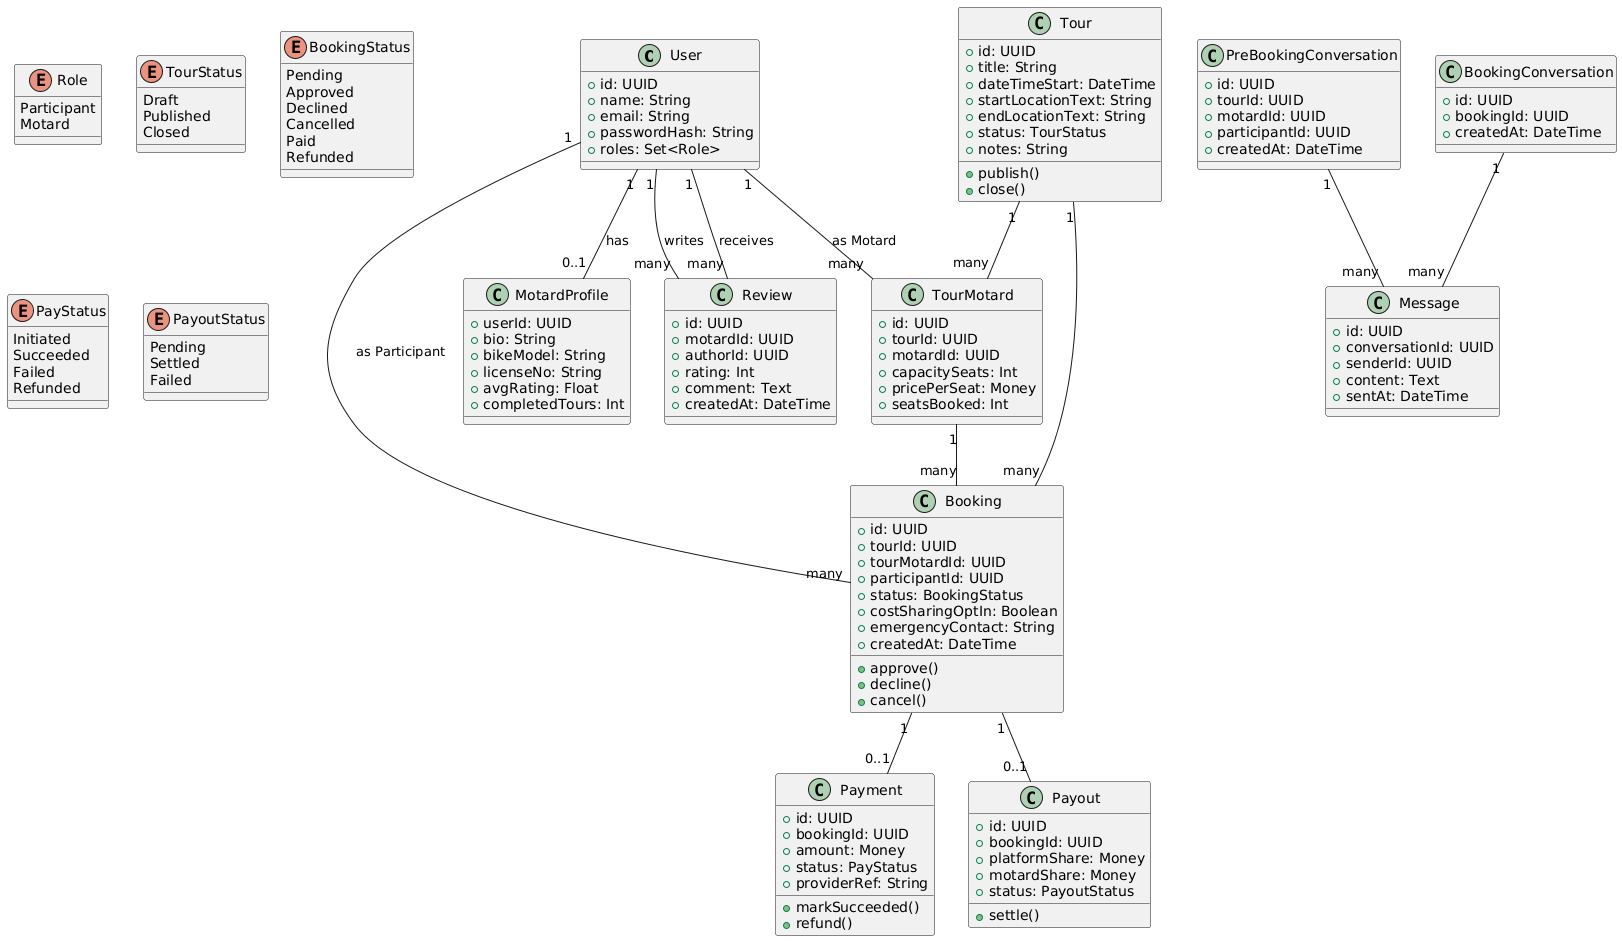

**Key changes vs previous version**

* Introduced **MotardProfile** (ratings/reviews/history).
* Introduced **TourMotard** (association class) to model **per-motard capacity & price** inside one tour group.
* **Booking** now targets a **specific motard in a tour** and stores a `costSharingOptIn` flag.
* **PreBookingConversation** (for chat before any booking) and **BookingConversation** (chat after request).
* **Payout** created on successful payment with **platformShare = 50%** and **motardShare = 50%** (mock settlement).

**PlantUML (Class Diagram)**

```plantuml
@startuml
class User {
  +id: UUID
  +name: String
  +email: String
  +passwordHash: String
  +roles: Set<Role>
}

enum Role {
  Participant
  Motard
}

class MotardProfile {
  +userId: UUID
  +bio: String
  +bikeModel: String
  +licenseNo: String
  +avgRating: Float
  +completedTours: Int
}

User "1" -- "0..1" MotardProfile : has

class Tour {
  +id: UUID
  +title: String
  +dateTimeStart: DateTime
  +startLocationText: String
  +endLocationText: String
  +status: TourStatus
  +notes: String
  +publish()
  +close()
}

enum TourStatus {
  Draft
  Published
  Closed
}

class TourMotard {
  +id: UUID
  +tourId: UUID
  +motardId: UUID
  +capacitySeats: Int
  +pricePerSeat: Money
  +seatsBooked: Int
}

Tour "1" -- "many" TourMotard
User "1" -- "many" TourMotard : as Motard

class Review {
  +id: UUID
  +motardId: UUID
  +authorId: UUID
  +rating: Int
  +comment: Text
  +createdAt: DateTime
}
User "1" -- "many" Review : receives
User "1" -- "many" Review : writes

class Booking {
  +id: UUID
  +tourId: UUID
  +tourMotardId: UUID
  +participantId: UUID
  +status: BookingStatus
  +costSharingOptIn: Boolean
  +emergencyContact: String
  +createdAt: DateTime
  +approve()
  +decline()
  +cancel()
}

enum BookingStatus {
  Pending
  Approved
  Declined
  Cancelled
  Paid
  Refunded
}

Tour "1" -- "many" Booking
TourMotard "1" -- "many" Booking
User "1" -- "many" Booking : as Participant

class Payment {
  +id: UUID
  +bookingId: UUID
  +amount: Money
  +status: PayStatus
  +providerRef: String
  +markSucceeded()
  +refund()
}
enum PayStatus {
  Initiated
  Succeeded
  Failed
  Refunded
}
Booking "1" -- "0..1" Payment

class Payout {
  +id: UUID
  +bookingId: UUID
  +platformShare: Money
  +motardShare: Money
  +status: PayoutStatus
  +settle()
}
enum PayoutStatus {
  Pending
  Settled
  Failed
}
Booking "1" -- "0..1" Payout

class PreBookingConversation {
  +id: UUID
  +tourId: UUID
  +motardId: UUID
  +participantId: UUID
  +createdAt: DateTime
}

class BookingConversation {
  +id: UUID
  +bookingId: UUID
  +createdAt: DateTime
}

class Message {
  +id: UUID
  +conversationId: UUID
  +senderId: UUID
  +content: Text
  +sentAt: DateTime
}

PreBookingConversation "1" -- "many" Message
BookingConversation "1" -- "many" Message

@enduml
```

**Key invariants**

* **1-to-1 booking:** `Booking.tourMotardId` must reference a `TourMotard` row (chosen motard within the tour).
* **Capacity guard:** For a given `TourMotard`, `seatsBooked ≤ capacitySeats`. Approving a booking increments `seatsBooked`.
* **Payment & confirmation:** Only after `Payment.status = Succeeded` can `Booking.status = Paid` and a **Payout** be created.
* **Payout split:** `platformShare = motardShare = Payment.amount * 0.5` (for MVP; make it configurable later).
* **Chats:**

  * Pre-booking chat uses **PreBookingConversation** keyed by `(tourId, motardId, participantId)`;
  * Post-request chat uses **BookingConversation** keyed by `bookingId`.
* **Visibility/ACLs:** Only the **participant** and the **selected motard** can see a given pre-booking or booking conversation.

---

# 0) project spine (what we keep constant)

* **Stack**: ASP.NET Core 8 (Web API or Razor Pages), EF Core, mysql (dev), Identity (auth), SignalR (chat later).
* **Core entities**: `User`, `MotardProfile`, `Tour`, `TourMotard`, `Booking`, `Payment(mock)`, `Payout(50/50)`, `PreBookingConversation`, `BookingConversation`, `Message`.
* **Key flows**: discover → pre-booking chat → 1-to-1 booking request (safety + emergency + cost-sharing flag) → approval → pay fixed price → confirm + payout.

---

# Stage A — “skeleton & diagrams lock”

**Goal:** lock logic before coding.

* ✅ Finalize **Use Case list & happy paths** (we already updated).
* ✅ Finalize **Class Diagram** (we already updated).
* Add 10–15 **business rules** as bullet points (capacity, payout split, cancellation windows, chat ACLs).
* Define **non-functional**: auth method, rate-limits, logging, i18n.

**Discuss / decide**

1. Cancellation rules (pre-payment vs post-payment?).
2. Refund policy (mock): always full refund if organizer cancels?
3. Booking expiry after approval (e.g., pay within 24h?).
4. Review eligibility (only after Paid + past tour start?).
5. Rate limit: max pre-booking conversations per participant per motard?

| Topic                                 | Decision (your spec)                                                                                                                                                                              |
| ------------------------------------- | ------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------- |
| **Pre-payment cancel**                | Participant or Motard can cancel **free** (no money → seat released).                                                                                                                             |
| **Post-payment cancel (Participant)** | **Default:** non-refundable. **However** Participant may **request motard to cancel**; if **motard agrees**, treat **as pre-payment** → full refund to participant, seat released, payout failed. |
| **Post-payment cancel (Motard)**      | **Full refund** to participant; payout marked **Failed**.                                                                                                                                         |
| **Tour cancelled by organizer**       | **All related bookings refunded** in full; all payouts failed.                                                                                                                                    |
| **Approval expiry / Pay-by**          | Participant must **pay within 6h** after approval; else auto-cancel (expired) and seat released.                                                                                                  |
| **Review eligibility**                | Allowed **only** if `Booking = Paid/Refunded` **and** tour start time has passed; 1 review per booking.                                                                                           |
| **Pre-booking chat rate limit**       | **Max 5 new pre-booking conversations/day** per participant (global). Also **1 active conversation per (tourId, motardId, participantId)** (reuse it).                                            |

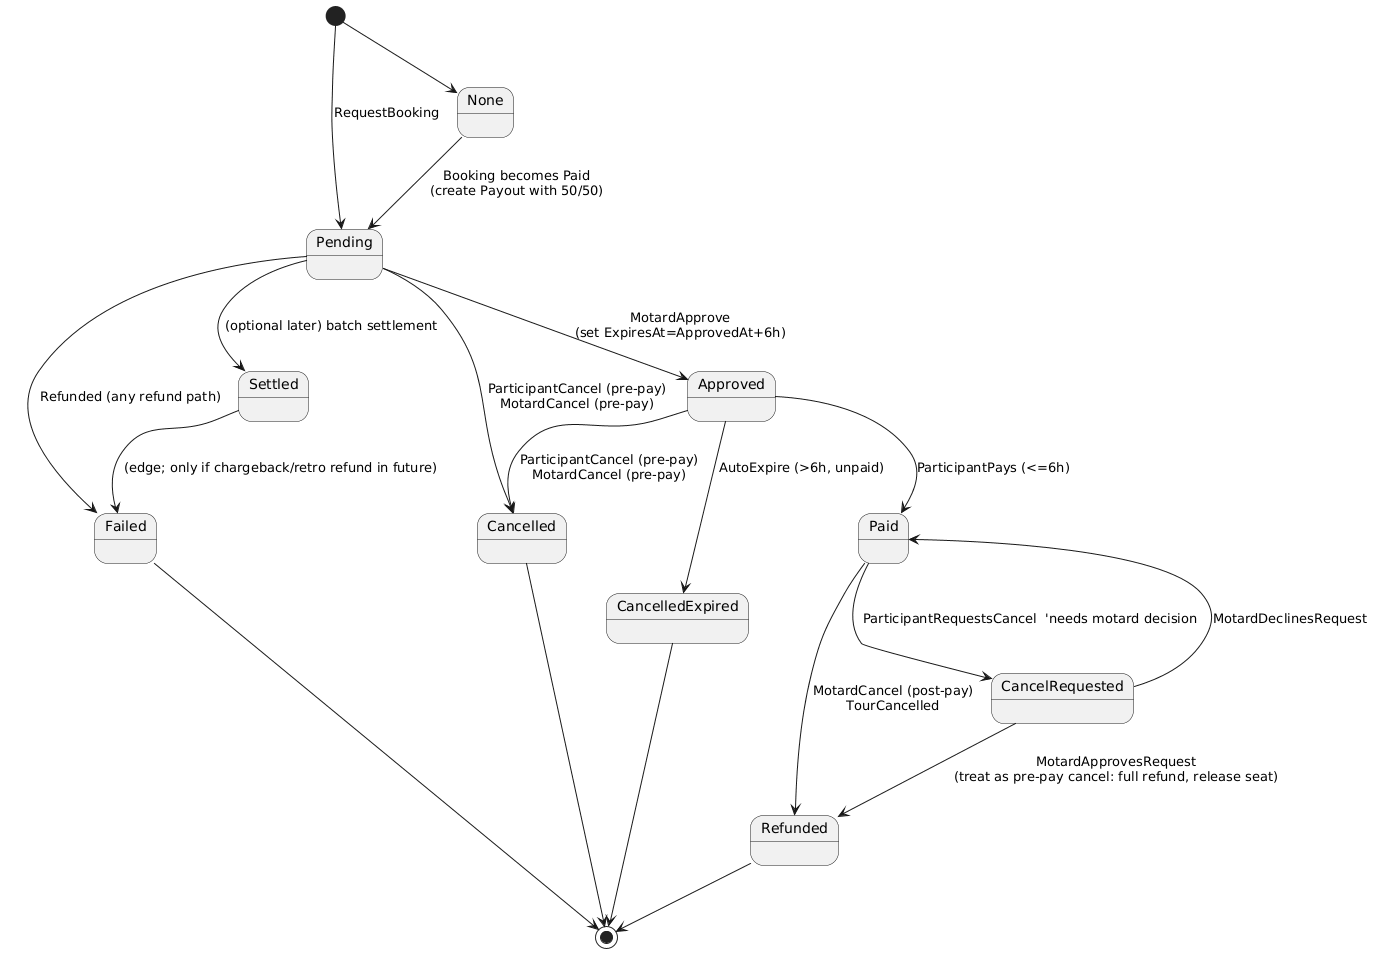

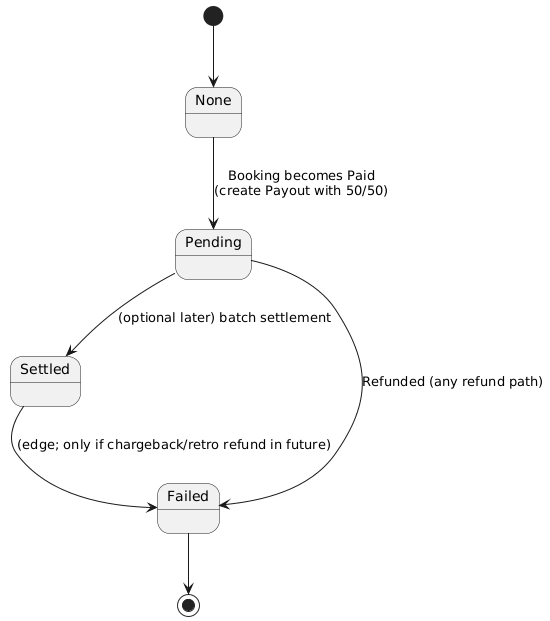

**Output:** “Spec v1” (md/ipynb cell) + finalized PlantUML.

---


# Stage B — Data & Migrations (plan)

## 1) Entities & key fields (final list for DB) (reuse ASP.NET Identity)

## **Data Models**

### **Booking**

| Field                  | Type / Enum                                                                                   | Description                                      |
| ---------------------- | --------------------------------------------------------------------------------------------- | ------------------------------------------------ |
| **Status**             | `Pending`, `Approved`, `Paid`, `CancelRequested`, `Cancelled`, `CancelledExpired`, `Refunded` | Booking lifecycle state                          |
| **ApprovedAt**         | UTC, nullable                                                                                 | Timestamp when motard approved                   |
| **ExpiresAt**          | UTC, nullable                                                                                 | Auto-cancel threshold (e.g., +6h after approval) |
| **CancellationReason** | short text (`participant`, `motard`, `tour-cancel`, `expired`)                                | Why booking was cancelled                        |
| **CostSharingOptIn**   | bool                                                                                          | Participant opted for cost sharing               |
| **TourId**             | FK                                                                                            | Linked tour                                      |
| **TourMotardId**       | FK                                                                                            | Linked motard                                    |
| **ParticipantUserId**  | FK                                                                                            | Linked participant                               |

---

### **Payment**

| Field           | Type / Enum                                    | Description                     |
| --------------- | ---------------------------------------------- | ------------------------------- |
| **Status**      | `Initiated`, `Succeeded`, `Failed`, `Refunded` | Payment state                   |
| **Amount**      | number                                         | Payment amount                  |
| **ProviderRef** | string                                         | Reference from payment provider |
| **PaidAt**      | UTC                                            | Payment timestamp               |

---

### **Payout**

| Field             | Type                           | Description                 |
| ----------------- | ------------------------------ | --------------------------- |
| **PlatformShare** | number                         | Platform’s share of payment |
| **MotardShare**   | number                         | Motard’s share of payment   |
| **Status**        | `Pending`, `Settled`, `Failed` | Payout status               |
| **SettledAt**     | UTC (future)                   | When payout was finalized   |

---

## **Conversation Limits**

* **PreBookingConversation** has **unique key:** `(TourId, MotardId, ParticipantId)`
* **Daily cap:** max **5 new conversations/day per participant**

  * Use a daily counter table or cached count
  * Key: `(ParticipantId, Date)`

---

## **Endpoints Checklist**

### **Booking Core**

| Endpoint                               | Action                 | Result                                                    |
| -------------------------------------- | ---------------------- | --------------------------------------------------------- |
| `POST /bookings/request`               | Create booking request | → `Pending`                                               |
| `POST /bookings/{id}/approve` (motard) | Approve booking        | → `Approved` + `ExpiresAt = +6h`                          |
| `POST /payments/pay/{bookingId}`       | Process payment        | → `Paid`, create `Payout(50/50)`, increment `SeatsBooked` |

---

### **Cancellation Flow**

#### **Pre-payment** (`Pending` / `Approved`)

| Endpoint                     | Actor                 | Result                       |
| ---------------------------- | --------------------- | ---------------------------- |
| `POST /bookings/{id}/cancel` | participant or motard | → `Cancelled` (release seat) |

#### **Post-payment (participant-initiated)**

| Endpoint                             | Actor       | Result                                                       |
| ------------------------------------ | ----------- | ------------------------------------------------------------ |
| `POST /bookings/{id}/request-cancel` | participant | → `CancelRequested`                                          |
| `POST /bookings/{id}/decide-cancel`  | motard      | Body: `approve` | `decline` → `Refunded` or revert to `Paid` |

#### **Post-payment (motard-initiated)**

| Endpoint                            | Actor  | Result       |
| ----------------------------------- | ------ | ------------ |
| `POST /bookings/{id}/cancel-motard` | motard | → `Refunded` |

#### **Tour cancel**

| Endpoint                  | Actor        | Result                                                 |
| ------------------------- | ------------ | ------------------------------------------------------ |
| `POST /tours/{id}/cancel` | system/admin | Cascade: all **Paid → Refunded**; others → `Cancelled` |

---

### **Expiry**

| Endpoint                      | Action                                                              |
| ----------------------------- | ------------------------------------------------------------------- |
| `POST /jobs/expire-approvals` | Any `Approved` past `ExpiresAt` → `CancelledExpired` (release seat) |

---

### **Reviews**

| Endpoint                         | Guard                                                                            |
| -------------------------------- | -------------------------------------------------------------------------------- |
| `POST /motards/{userId}/reviews` | Must have a **Paid/Refunded** booking; **tour start < now**; **one per booking** |

---

### **Pre-booking Conversations**

| Endpoint                                                | Rule                                                                                |
| ------------------------------------------------------- | ----------------------------------------------------------------------------------- |
| `POST /prebooking/conversations`                        | Create if **daily count < 5** and no existing (tour,motard,participant); else reuse |
| `POST /prebooking/messages`, `GET /prebooking/messages` | ACL: only between motard & participant                                              |

---

## **Capacity & Seat Integrity (Invariants)**

| Event                                         | Seat Logic                                                     |
| --------------------------------------------- | -------------------------------------------------------------- |
| **On Approve (pre-pay)**                      | Do **not** increment seats yet                                 |
| **On Paid**                                   | `SeatsBooked++` **iff** `< CapacitySeats`, else reject payment |
| **On Cancelled / CancelledExpired (pre-pay)** | No seat change                                                 |
| **On Refunded (post-pay)**                    | `SeatsBooked--` (never below 0)                                |

---

## **Booking State Machine**

```
Pending → Approved → Paid → (CancelRequested) → Refunded | Paid
                      ↘
                       Cancelled | CancelledExpired | CancelDeclined
```

---

## **Tour Status**

```
Draft | Published | Closed | Cancelled
```

* On **Cancelled**, block new bookings and prevent payments.

---

## **Timestamps (Auditable)**

| Entity      | Fields                                                                                              |
| ----------- | --------------------------------------------------------------------------------------------------- |
| **Booking** | `CreatedAt`, `ApprovedAt`, `ExpiresAt`, `PaidAt`, `CancelledAt`, `RefundedAt`, `LastStatusChangeAt` |
| **Payment** | `PaidAt`                                                                                            |
| **Payout**  | `SettledAt`                                                                                         |

---

## **Payment Race & Expiry Guard**

At payment time:

* Reject if `Now > ExpiresAt`
* Reject if `Status != Approved`

→ Prevents late payments after auto-cancel.

---

## **Idempotency**

* Accept `Idempotency-Key` header for `/payments/pay/{bookingId}`
* If same key retried → return first result

---

## **Pre-booking Daily Cap**

* Track `(ParticipantId, Date)`
* Enforce: max **5 new conversations/day**

---

## Booking + Payment + Payout — state machine (MVP)

Use this as the single source of truth for transitions you’ll enforce in code later.

**States (Booking.Status):**
`Pending → Approved → Paid → (Refunded)`
Terminal non-paid: `Declined | Cancelled | CancelledExpired`

**Transitions (who triggers → preconditions → effects):**

* **Pending → Approved** (Motard approves)

  * Tour.Status ∈ {Published}; SeatsBooked < CapacitySeats; booking still Pending
  * Set `ApprovedAt=now`, `ExpiresAt=ApprovedAt+6h`
* **Approved → Declined** (Motard declines)

  * Set `CancelledAt=now`
* **Approved → Cancelled** (Participant or Motard cancels pre-pay)

  * Seat not counted yet; set `CancelledAt=now`
* **Approved → CancelledExpired** (system job)

  * `now > ExpiresAt`; set `CancelledAt=now`
* **Approved → Paid** (Participant pays successfully)

  * `now ≤ ExpiresAt`; Payment succeeds; SeatsBooked < CapacitySeats
  * Set `PaidAt=now`; increment `TourMotard.SeatsBooked += 1`; create `Payout(50/50, Pending)`
* **Paid → Refunded**

  * *Motard cancels post-pay*, or *Motard approves participant’s cancel request*, or *Tour cancelled*
  * Payment→Refunded; Payout→Failed; `SeatsBooked -= 1 (≥0)`; `RefundedAt=now`
* **Paid → Paid** (participant cancel request declined)

  * Set `CancelDecision=DeclinedByMotard` (Status stays `Paid`)

**Payout.Status:**
`Pending → Settled | Failed`

* Created when Booking → Paid (PlatformShare = MotardShare = Amount * 0.5).
* Set to **Failed** on any refund; **Settled** is future work.

![image-3.png](attachment:image-3.png)


```plantuml
@startuml
[*] --> Pending
Pending -down-> Approved : approve (motard)\nset ExpiresAt=+6h
Pending --> Declined : decline (motard)
Pending --> Cancelled : cancel pre-pay (participant/motard)

Approved --> Paid : pay success (<= ExpiresAt AND seats available)\n+ Payment.Succeeded + Payout.Pending + SeatsBooked++
Approved --> Cancelled : cancel pre-pay (participant/motard)
Approved --> CancelledExpired : expire job (now > ExpiresAt)

Paid --> Refunded : motard cancels OR tour cancelled OR motard approves cancel request\n+ Payment.Refunded + Payout.Failed + SeatsBooked--
Paid --> Paid : motard declines cancel request\nCancelDecision=DeclinedByMotard

Cancelled --> [*]
CancelledExpired --> [*]
Declined --> [*]
Refunded --> [*]
@enduml
```

---

## 2) Constraints & checks (copy straight into your IPYNB notes)

* **FKs** everywhere; cascade delete *off* for safety (use explicit deletes).
* **TourMotard**: `SeatsBooked <= CapacitySeats`. (DB CHECK ideal, but enforce in app w/ transaction.)
* **Booking → Payment/Payout**: 1:1 via unique FKs.
* **Message**: CHECK `( (PreBookingConversationId IS NOT NULL) XOR (BookingConversationId IS NOT NULL) )`.
* **Review**: FK to `BookingId` and to `MotardUserId`; enforce booking was `Paid` or `Refunded`, and tour start < NOW (enforce in app).
* **Payment at pay time** must verify: `Status == Approved`, `Now <= ExpiresAt`, and `SeatsBooked < CapacitySeats`.

**Transactions / concurrency**

* On **pay**: do all updates in one transaction:

  1. Re-read booking with `FOR UPDATE`.
  2. Re-check `Status == Approved` and `Now <= ExpiresAt`.
  3. Re-read `TourMotard.SeatsBooked < CapacitySeats`.
  4. Create `Payment(Succeeded)`, set `Booking.Status = Paid`, increment `SeatsBooked`, create `Payout(50/50)`.
* If refund: decrement `SeatsBooked` (min 0), set `Payment=Refunded`, `Booking=Refunded`, set `Payout=Failed`.

---

## EF Core configuration — checklist (tell Copilot to implement)

**DbContext.OnModelCreating**

* **TourMotard**

  * `HasIndex(x => new { x.TourId, x.MotardUserId }).IsUnique();`
* **Booking**

  * FK: `TourId`, `TourMotardId`, `ParticipantUserId`
  * Enum conversions (if you use string or int)
  * Optional: add a concurrency token (`RowVersion` byte[]) to guard concurrent pays/approvals
* **Payment**

  * One-to-one: `HasOne(p => p.Booking).WithOne(b => b.Payment).HasForeignKey<Payment>(p => p.BookingId).IsRequired();`
  * Unique: `(BookingId)`
  * Optional unique on `(ProviderRef)` when not null
* **Payout**

  * One-to-one: `HasOne(p => p.Booking).WithOne(b => b.Payout).HasForeignKey<Payout>(p => p.BookingId).IsRequired();`
  * Unique: `(BookingId)`
* **PreBookingConversation**

  * Unique index `(TourId, MotardUserId, ParticipantUserId)`
* **BookingConversation**

  * Unique index `(BookingId)`
* **Message**

  * Two optional FKs: `PreBookingConversationId?`, `BookingConversationId?`
  * **CHECK constraint** (mysql/SQL Server): XOR: exactly one FK set

    * If DB-level CHECK is tricky, enforce in service + add validation
* **Review**

  * Unique index `(BookingId)` (one review per booking)
* **RateLimitCounter**

  * Unique `(ParticipantUserId, Date)`

**Column types**

* Money: `decimal(10,2)` for `PricePerSeat`, `Payment.Amount`, `Payout.PlatformShare`, `Payout.MotardShare`
* Timestamps: UTC `DateTime`

**Delete behavior**

* Prefer **Restrict** on FKs (no cascade) to avoid accidental cascades; write explicit deletes in services.

**Transactions**

* Document: “The **pay** flow is transactional: re-check status/expiry/capacity, then create `Payment`, set `Booking=Paid`, `SeatsBooked++`, create `Payout`.”

---

## 3) Seed plan (for your class demo)
* **Users**: one Motard (with MotardProfile) + one Participant.
* **Tour**: 1 demo tour (Published).
* **TourMotard**: two rows (Motard A: capacity 1, 20€(can be set by the motard); Motard B: capacity 3, 10€).
* **PreBookingConversation**: one with a hello message.
* **No bookings** initially (you’ll create them live).

## Seed data — outline Copilot can fill

**Users**

* `MotardA` (email: motardA@test), password (dev), role: Motard
* `MotardB` (email: motardB@test), role: Motard
* `ParticipantX` (email: participant@test), role: Participant

**MotardProfile**

* For `MotardA` and `MotardB` (with `LicenseNo`, `BikeModel`, simple `Bio`)

**Tour**

* `Tour#1`: Title “Normandy Coast Loop”, `StartAt = <next Saturday 10:00 UTC>`, `Status=Published`, start/end locations as text

**TourMotard**

* `Tour#1` + `MotardA`: `CapacitySeats=1`, `PricePerSeat=20.00`, `SeatsBooked=0`
* `Tour#1` + `MotardB`: `CapacitySeats=3`, `PricePerSeat=10.00`, `SeatsBooked=0`

**PreBookingConversation** (optional)

* For `(Tour#1, MotardA, ParticipantX)` with one `Message: "Hi, what gear should I bring?"`

> Seed via `ModelBuilder.Entity<T>().HasData(...)` or a dedicated seeding routine after `db.Database.Migrate()`.

---

## 4) Migration & smoke tests (DoD)

1. Create DB & run **initial migration** without errors.
2. Query smoke tests (via SQL client or LINQPad):

   * Count rows in each table (seed present).
   * Ensure **Unique** indexes exist (`TourId, MotardUserId`, PreBooking unique key, etc.).
   * Insert a **Message** with both conversation IDs → should **fail** (constraint OK).
3. Quick manual flows (via Swagger/Postman after you wire minimal endpoints):

   * Create **Booking** (Pending) → **Approve** sets `ExpiresAt=+6h`.
   * Try **Pay** after changing `ExpiresAt` to past → should **reject**.
   * Valid **Pay** → creates Payment(Succeeded), Payout(Pending), increments SeatsBooked.
   * **Motard cancel** post-pay → Payment→Refunded, Booking→Refunded, Payout→Failed, SeatsBooked--.
   * **Tour cancel** → cascade logic applied: Paid→Refunded, others→Cancelled.
---
# Implementation plan
## Stage B — step-by-step order (no code until you’re ready)

**Step B-0 — Freeze the schema doc**

* Put the tables, keys, indexes, constraints above into your IPYNB “Spec v1”.
* Copy the **state machine** + **invariants** into the same file.

**Step B-1 — Create entity classes & DbContext**

* Ask Copilot to generate entities with fields and enums exactly as specified.
* Add `AppDb : IdentityDbContext<AppUser>` and `DbSet<>` for each table.

**Step B-2 — Implement OnModelCreating configuration**

* Tell Copilot to add all indexes, one-to-ones, and the **Message XOR** check (or a TODO if CHECK is tricky).
* Ensure money columns as `decimal(10,2)`.

**Step B-3 — Add the seed data**

* Use `HasData` or a seed method post-migrate.
* Include **3 users**, **2 profiles**, **1 tour**, **2 tour-motards**, **1 prebooking conversation + message**.

**Step B-4 — Generate & apply the initial migration**

```bash
dotnet ef migrations add Init
dotnet ef database update
```

**Step B-5 — Smoke test the DB** (no API yet)

* Open the DB (mysql server) and check: tables exist, indexes exist (unique ones too).
* Verify seed rows (counts).
* Attempt to insert a `Message` with both conversation IDs → should be blocked (if CHECK exists). If not implemented at DB level, note the TODO to enforce in service.

**Step B-6 — Capture screenshots / notes**

* Add a quick table list + counts into your IPYNB as proof of Stage B completion.
 
## 1. Table & Index Verification
- All expected tables exist: `AppUser`, `MotardProfile`, `Tour`, `TourMotard`, `Booking`, `Payment`, `Payout`, `PreBookingConversation`, `BookingConversation`, `Message`, `Review`, `IdempotencyKey`, `RateLimitCounter`.
- Unique indexes verified (e.g., `TourMotard` on `(TourId, MotardUserId)`, `PreBookingConversation` on `(TourId, MotardUserId, ParticipantUserId)`).
- Message XOR constraint enforced (service-level and DB-level where supported).

## 2. Seed Data & Row Counts
- Seeded test data for tours, motards, bookings, and conversations.
- Example row counts (from test runs):
  - Tours: 1
  - TourMotards: 2
  - Bookings: 2 (one Paid, one Pending)
  - Payments: 1 (Paid)
  - Payouts: 1 (Pending)
  - PreBookingConversations: 1
  - Messages: 1

## 3. Smoke Test Results
- All booking/payment/payout flows pass:
  1. Approve → Pay → Confirm: Payment and Payout created, seats incremented.
  2. Pay after ExpiresAt: Payment rejected, no state change.
  3. Motard cancels post-pay: Payment refunded, payout failed, seats decremented.
  4. Tour cancel cascade: Paid bookings refunded, pending bookings cancelled.
- No constraint violations; Message XOR logic blocks invalid inserts.

## 4. Example Query Outputs
```sql
-- Count rows in key tables
SELECT COUNT(*) FROM Tour;
SELECT COUNT(*) FROM TourMotard;
SELECT COUNT(*) FROM Booking;
SELECT COUNT(*) FROM Payment;
SELECT COUNT(*) FROM Payout;
SELECT COUNT(*) FROM PreBookingConversation;
SELECT COUNT(*) FROM Message;
```

All counts match expected seed/test data.

## 5. Test Summary
- All unit tests pass (7/7):
  - PaymentService and BookingPaymentFlows cover all business rules and state transitions.
- No errors or warnings in migration or test runs.

## 6. Next Steps
- Ready to proceed to Stage C (public read API) and Stage D (booking write flow).
- Optionally: add integration tests for idempotency middleware and generate DB migration scripts for production.

---

## Optional “gotchas” to note now (save you time later)

* **Expiry race**: ensure pay endpoint double-checks `ExpiresAt`.
* **SeatsBooked underflow**: on refund, clamp `max(SeatsBooked-1, 0)`.
* **Idempotency**: log `Idempotency-Key` per booking to prevent double pay.
* **Timezones**: always UTC in DB; format for UI later.
* **One seat per booking**: document it in spec & UI copy to avoid confusion.

---



# Stage C — “public read API”

**Goal:** demoable read endpoints + Swagger.

* `GET /tours?date=…&area=…&priceMax=…`
* `GET /tours/{id}` (includes motards with capacity/price)
* `GET /motards/{userId}` (profile + stats + reviews)
* `GET /tours/{id}/motards` (the group list)

**Discuss / decide**

* Simple text area filter vs polygon/geo later (stick to text now).

**DoD**

* Swagger lists endpoints; basic filtering works.

---

# Stage D — “booking write flow (happy path)”

**Goal:** end-to-end 1-to-1 booking to a chosen motard.

* `POST /bookings/request`
  body: `{ tourId, tourMotardId, emergencyContact, costSharingOptIn }`
* `POST /bookings/{id}/approve` (motard only; capacity guard)
* `POST /payments/pay/{bookingId}` (mock → marks Paid, increments `SeatsBooked`, creates `Payout` with 50/50)
* `GET /bookings/{id}` returns full booking state

**Discuss / decide**

* Approval failure messages (no seats left, profile missing, tour closed).
* Booking expires if not paid after X hours?

**DoD**

* New booking can be created → approved → paid.
* DB shows `Payment.Succeeded` and `Payout(50/50)`.

---

# Stage E — “chats & ACLs”

**Goal:** minimal but correct separation.

* **Pre-booking chat**: create/find `PreBookingConversation(tourId, motardId, participantId)`; `POST /prebooking/messages`.
* **Booking chat**: `BookingConversation(bookingId)`; `POST /booking/messages`.
* Add simple **ACL checks** (only participant/motard can read/write).

**Discuss / decide**

* UI experience: show a single thread with a divider when booking is created (backend still stores two conversations).
* Rate limit + spam guard.

**DoD**

* You can post/read messages for both contexts; wrong users get 403.

---

# Stage F — “auth, roles, and guardrails”

**Goal:** make it realistic for class.

* Identity setup with seed users.
* Policy attributes: `[Authorize(Roles="Motard")]` for tour creation & approval.
* `[Authorize]` for booking/chat.

**Discuss / decide**

* JWT vs Cookies (for simple class demo, cookies may be enough).
* Minimum profile fields to act as Motard (e.g., require `licenseNo`?).

**DoD**

* Unauthorized calls blocked; role-guarded endpoints enforced.

---

# Stage G — “cancellation/refund & reviews (light)”

**Goal:** round out the flow.

* `POST /bookings/{id}/cancel` (participant before payment → free; after payment → non-refundable or partial, per rule)
* `POST /bookings/{id}/refund` (organizer cancel → full refund (mock), payout status adjusts)
* `POST /motards/{id}/reviews` (if participant had a Paid booking in the past for this motard)

**Discuss / decide**

* A simple rule table you can show in class (who cancels? when? outcome?).
* Review moderation (skip in MVP).

**DoD**

* Simple state transitions work; payouts flip to `Pending/Failed` if refunded (mock logic).

---

# Stage H — “demo storyboard & test checklist”

**Goal:** teacher-friendly demo that hits the learning objectives.

**Storyboard (5–7 minutes)**

1. Show 1 tour with **2 motards** (capacity 1 vs 3; price 20€ vs 10€).
2. As participant: open motard profile → pre-booking chat question.
3. Send **booking request** to motard A (1-to-1).
4. As motard A: **approve** → system returns **payment link** (mock).
5. As participant: **pay** → booking turns **Paid**, **Payout 50/50** created.
6. Switch to **booking chat** to agree meeting point.
7. (Optional) Organizer cancels another booking → mock refund → payout updates.

**Test checklist**

* Capacity: approving beyond capacity returns 400.
* Booking to a **published** tour only.
* Only chosen motard can approve that booking.
* Payment creates payout = exact half/half of seat price.
* Chat visibility restricted by role & context.
* Cancellation rules applied correctly.

---

## Questions for us to iterate (short list)

1. **Approval expiry**: after approval, how long does the participant have to pay? (e.g., 24h)
2. **Cancellation matrix** (who/when/outcome): do you want a 3×3 table now?
3. **Minimum motard profile**: require `licenseNo` before listing?
4. **Rate limits**: max pre-booking messages/conversations per hour?
5. **Booking identifier** formatting for the UI (e.g., `BK-2025-00012`)?
6. **i18n**: EN default with FR/中文 later, or start bilingual?

---

## What to do next (your immediate tasks)

* Put **Stage A Spec v1** (rules + PlantUML) into your ipynb.
* Decide the **cancellation matrix** + **approval expiry** (just numbers!).
* Confirm **auth mode** (cookies vs JWT) for class constraints.

when you have those tiny decisions, i’ll tighten the ruleset (pre/post-conditions per UC + a small state machine for `Booking`/`Payout`) so Copilot can scaffold cleanly.